In [23]:
from graph_loader import get_graph
from utils.graph_processing import GraphProcessor, get_weights, create_multidigraph_from_df
import networkx as nx
import osmnx as ox
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import folium
import matplotlib.colors as mcolors


%matplotlib inline

In [2]:
G = get_graph("Wrocław, Poland", "wroclaw.graphml")

Loading graph from graphs/wroclaw.graphml


In [3]:
gp = GraphProcessor(G)

In [4]:
G_filled = gp.fill(
    cols = {
    'maxspeed': 50,
    'lanes': 2
    },
    collection_values= {
        'maxspeed': 'mean',
        'lanes': 'min'
    },
    inplace=True,
    k=0.5
)

In [5]:
df = gp.to_dataframe(cols=['source', 'target', 'maxspeed', 'lanes', 'length', 'weight'])
df

,source,target,maxspeed,lanes,length,weight
0,95584835,241778108,50.0,2,30.730,0.020833
1,95584835,297779709,50.0,2,178.450,0.020833
2,95584841,164895026,50.0,2,14.714,0.020833
3,95584841,268480775,50.0,2,125.889,0.020833
4,95584850,95584855,50.0,3,25.991,0.027778
...,...,...,...,...,...,...
17169,12693106629,9762385114,50.0,2,109.789,0.020833
17170,12714793091,7026659260,50.0,2,485.115,0.020833
17171,12737276722,163081342,50.0,3,236.437,0.027778
17172,12744395471,245970549,50.0,2,31.169,0.020833


In [6]:
df.describe()

,source,target,maxspeed,lanes,length,weight
count,1.717400e+04,1.717400e+04,17174.000000,17174.000000,17174.000000,17174.000000
mean,1.767261e+09,1.766355e+09,40.954495,2.004251,141.804024,0.017136
std,2.392399e+09,2.393440e+09,11.431253,0.429824,188.572158,0.005750
min,9.558484e+07,9.558484e+07,5.000000,1.000000,0.906000,0.002083
25%,2.988971e+08,2.988971e+08,30.000000,2.000000,48.830000,0.012500
50%,3.920628e+08,3.920628e+08,50.000000,2.000000,100.258500,0.020833
75%,2.469764e+09,2.469294e+09,50.000000,2.000000,178.083500,0.020833
max,1.275299e+10,1.275299e+10,120.000000,7.000000,7485.842000,0.066667


Text(0.5, 1.0, 'Weight distribution for routes')

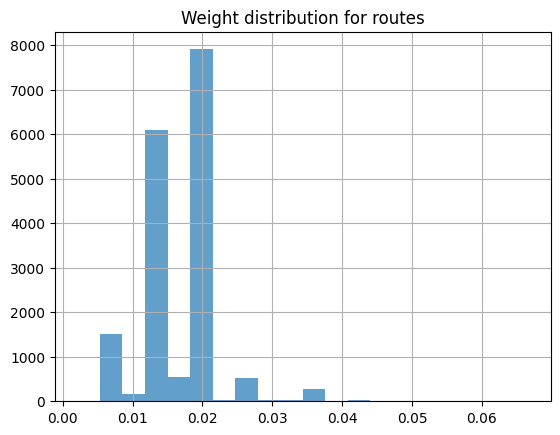

In [14]:
df['weight'].hist(
    bins = 20,
    alpha = 0.7
)

plt.title('Weight distribution for routes')

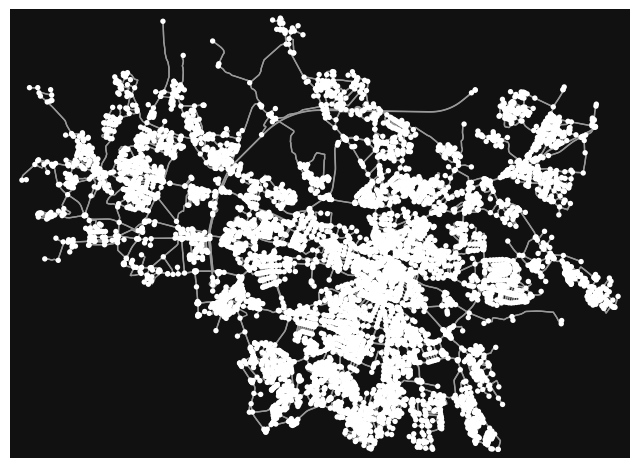

(<Figure size 800x800 with 1 Axes>, <Axes: >)

In [8]:
ox.plot_graph(G)

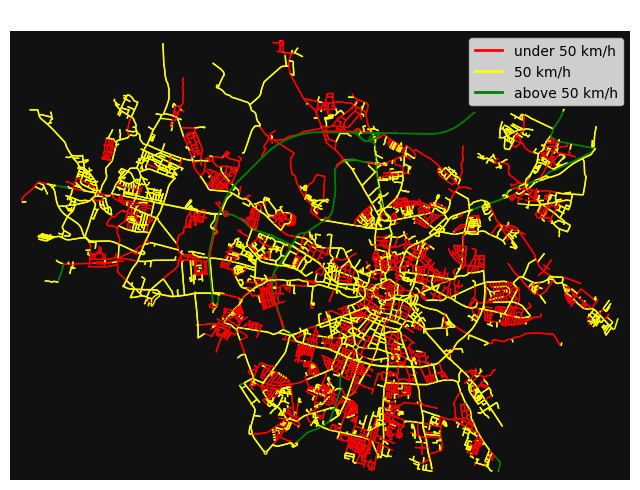

In [13]:
edge_colors = []

for u, v, key, data in G.edges(keys=True, data=True):
    maxspeed = data.get('maxspeed', None)
    
    color = None

    if maxspeed < 50:
        color = 'red'
    elif maxspeed == 50:
        color = 'yellow'
    elif maxspeed > 50:
        color = 'green'
        
    edge_colors.append(color)

fig, ax = ox.plot_graph(G, edge_color=edge_colors, show=False, close=False, node_size=0)

red_handle = mlines.Line2D([], [], color='red',   linewidth=2, label='under 50 km/h')
yellow_handle = mlines.Line2D([], [], color='yellow',linewidth=2, label='50 km/h')
green_handle = mlines.Line2D([], [], color='green', linewidth=2, label='above 50 km/h')

plt.title('Allowed speed', color='white')

ax.legend(handles=[red_handle, yellow_handle, green_handle], loc='upper right')

plt.show()

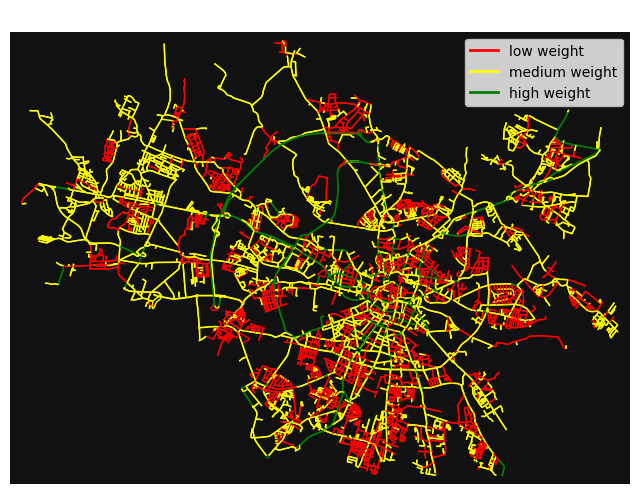

In [13]:
edge_colors = []

for u, v, key, data in G.edges(keys=True, data=True):
    weight = data.get('weight', None)
    
    color = None

    if weight < 0.013:
        color = 'red'
    elif weight < 0.021:
        color = 'yellow'
    else:
        color = 'green'
        
    edge_colors.append(color)

fig, ax = ox.plot_graph(G, edge_color=edge_colors, show=False, close=False, node_size=0)

red_handle = mlines.Line2D([], [], color='red',   linewidth=2, label='low weight')
yellow_handle = mlines.Line2D([], [], color='yellow',linewidth=2, label='medium weight')
green_handle = mlines.Line2D([], [], color='green', linewidth=2, label='high weight')

plt.title('Weights distribution for routes', color='white')

ax.legend(handles=[red_handle, yellow_handle, green_handle], loc='upper right')

plt.show()

In [10]:
largest_scc = max(nx.strongly_connected_components(G), key=len)
G = G.subgraph(largest_scc)

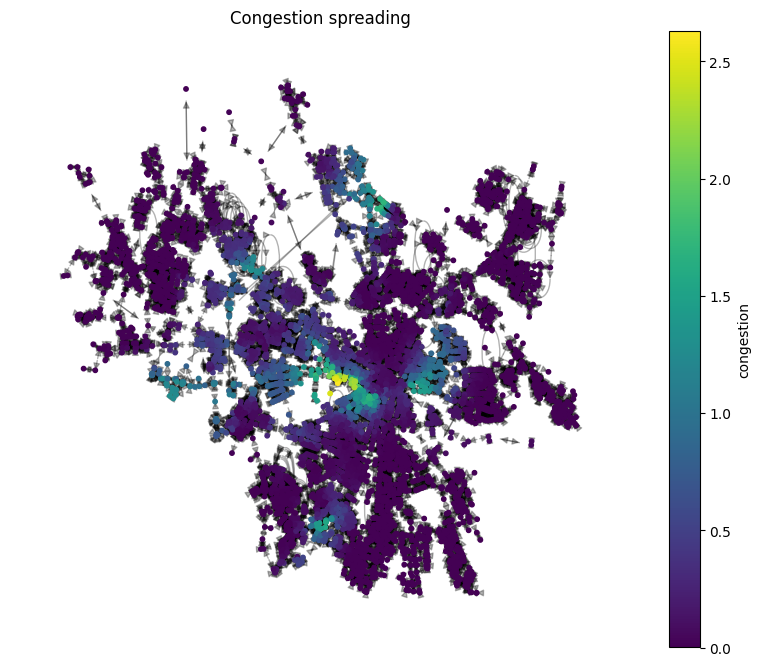

In [19]:
for node in G.nodes():
    G.nodes[node]['congestion'] = 0.0

edges_sorted_by_weight = sorted(list(G.edges(data=True)), key=lambda n: n[2]['weight'], reverse=True)
for most_weight_edges in edges_sorted_by_weight[:20]:
    initial_node = G.nodes()[most_weight_edges[0]]
    initial_node['congestion'] = 100.0

alpha = 0.6
num_steps = 100

for step in range(num_steps):

    congestion_old = {node: G.nodes[node]['congestion'] for node in G.nodes()}
    
    for node in G.nodes():
        neighbors = list(G.neighbors(node))
        if neighbors:
            avg_neighbor_cong = sum(congestion_old[n] for n in neighbors) / len(neighbors)
        else:
            avg_neighbor_cong = 0.0
        
        G.nodes[node]['congestion'] = (1 - alpha) * congestion_old[node] + alpha * avg_neighbor_cong

pos = {node: (data['x'], data['y']) for node, data in G.nodes(data=True)}

node_congestion = [G.nodes[node]['congestion'] for node in G.nodes()]


plt.figure(figsize=(10, 8))
nodes = nx.draw_networkx_nodes(G, pos, node_size=10, node_color=node_congestion,
                                )
nx.draw_networkx_edges(G, pos, alpha=0.3)
plt.title("Congestion spreading")
plt.colorbar(nodes, label="congestion")
plt.axis("off")
plt.show()

In [27]:
vmin, vmax = 0.0, 2.5

cmap = plt.get_cmap('inferno')
norm = mcolors.Normalize(vmin=vmin, vmax=vmax)

def congestion_color(c):
    rgba = cmap(norm(c))
    return mcolors.to_hex(rgba)

lons = [pos[n][0] for n in G.nodes()]
lats = [pos[n][1] for n in G.nodes()]
center = [sum(lats)/len(lats), sum(lons)/len(lons)]
m = folium.Map(location=center, zoom_start=13)

for node, (lon, lat) in pos.items():
    c = G.nodes[node]['congestion']
    folium.CircleMarker(
        location=[lat, lon],
        radius=3 + (c / vmax) * 5,
        fill=True,
        fill_color=congestion_color(c),
        fill_opacity=0.8,
        color=None
    ).add_to(m)


m.save('congestion_map.html')
m